# [실습] 월별 테마 추이 — 원문을 확인할 달

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 질문과 데이터

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">비정형 데이터(자연어) · 월별 비율 추이와 드릴다운</div>
<h1 style="color:#000000;margin:10px 0">월별 테마 추이 — 원문을 확인할 달</h1>
<div style="font-size:1.05em;color:#656565">테마 4개마다 두 달의 비율을 앞 달 대비 배수와 두 달 차이의 95% 구간으로 비교하고, 10월 건수가 줄어든 이유를 일별 건수로 찾습니다. 예식 테마 2월의 원문을 읽고, 기준을 고친 코드북을 버전으로 기록합니다</div>
</div>

**핵심 질문** 테마 비율이 바뀐 달은 민원의 주제가 바뀐 것일까요, 주제와 상관없는 이유로 비율만 바뀐 것일까요?

분모가 줄었거나, 영업일이 적거나 자료가 끊겼거나, 한 판매처의 민원이 절반을 넘었거나, 버전이 바뀌어도 건수나 비율이 달라집니다. 이론에서 배운 확인할 4가지를 민원 표본 2만 건의 테마 비율에 차례로 적용합니다. 계산하는 코드는 모두 준비되어 있고, 출력된 표와 그림을 보고 판단을 적습니다.

**이 실습에서 연습하는 것**: 테마 비율이 바뀐 달이 우연인지 95% 구간으로 확인하고, 달력 · 원문 · 버전 기록에서 이유를 찾는 법

**이 실습에서 할 일**

| 단계 | 할 일 | 채울 변수 |
|---|---|---|
| 1 | 테마 4개의 두 달 비율을 비교해 차이가 확실한 테마와 원문을 확인할 테마 고르기 | `MY_BEYOND` · `MY_CHECK` |
| 2 | 일별 건수로 10월 접수가 이어진 마지막 날과 영업일당 건수 구하기 | `MY_LAST_DAY` · `MY_BIZ_RATE` |
| 3 | 예식 테마 2월의 증가가 한 판매처 집중인지 판단하기 | `MY_CONCENTRATED` · `MY_WHY` |
| 4 | 예식 테마 기준을 다시 쓴 코드북의 버전 기록 채우기 | `MY_VERSION` |

- 진행: 셀을 위에서부터 실행합니다. 단계마다 「직접 해 보기」 셀의 변수에 답을 적고, 바로 아래 확인 셀을 실행합니다.
- 막히면: 확인 셀이 출력한 「고칠 것」을 먼저 읽고, 그래도 막히면 그 단계의 접힌 「자세히」를 열어 예시 답을 봅니다.
- 퀴즈: 단계 1 과 단계 3 에 2문항씩, 단계 4 에 1문항 있습니다. 퀴즈는 과제 점수와 별개이고, 답을 내면 바로 해설이 나옵니다.
- 제출: 단계 1～4 의 변수를 모두 채우고 확인 셀을 실행한 상태로 맨 아래 「실습 제출」 과제에서 제출합니다. 답이 예시 답과 달라도 결과가 출력되면 점수를 받습니다. 비워 둔 변수는 안내만 출력되어 점수를 받지 못합니다.

**실행 안내**

- LMS 에서는 셀을 위에서부터 차례로 실행합니다. 이 실습은 모델을 호출하지 않아 GPU 가 필요 없습니다.
- Colab 이나 내 컴퓨터에서 열었다면 맨 위 설치 셀부터 실행합니다. 처음 한 번은 민원 원자료(67.9MB)를 받느라 30초 안팎 걸립니다.
- 확인 셀은 변수를 아직 채우지 않아도 오류 없이 안내만 출력합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/9/97/Unicode_Web_growth.svg" alt="2001～2012년 웹 문서의 문자 인코딩 비율을 5개 선으로 그린 그래프. 빨간 ASCII only 는 57% 에서 16% 로 내려가고, 하늘색 UTF-8 은 0% 에서 64% 로 높아진다" width="620" height="353"/>
<p align="center"><em>▲ Google 이 측정한 웹 문서의 문자 인코딩 비율(2001～2012)이다. 해마다 5개 선을 더하면 100% 라, 하늘색 UTF-8 이 높아진 만큼 다른 선이 내려갔다. 테마 비율도 그 달 표본 전체를 분모로 한 비율이다 (출처: Wikimedia Commons, Unicode_Web_growth.svg, Chris55, CC BY-SA 4.0)</em></p>

In [1]:
# 실습 준비: 설치·폰트. 폰트 설치는 Colab 에서만 합니다
#  이 실습은 새로 설치하는 패키지가 없습니다. 원자료와 토픽 배정 파일을 pandas 로 읽고 집계만 하므로
#  모델 · Kiwi · BERTopic 이 필요 없습니다. pandas · pyarrow · numpy · matplotlib 은 Colab 기본 버전을 그대로 쓰고,
#  Colab 에서는 한글 폰트만 설치합니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")

# 한글 폰트: Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 직접 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 바뀌어 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색: 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

from importlib.metadata import version as _ver, PackageNotFoundError
_need = ["pandas", "pyarrow", "numpy", "matplotlib"]
_have = {}
for _name in _need:
    try:
        _have[_name] = _ver(_name)
    except PackageNotFoundError:
        _have[_name] = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 |", " · ".join(f"{k} {v}" for k, v in _have.items()))
_miss = [k for k in _need if _have[k] == "없음"]
if _miss:
    print("참고: 설치되지 않은 패키지가 있습니다(" + " · ".join(_miss) + "). Colab 에는 모두 설치되어 있고,"
          " 내 컴퓨터라면 pip 로 설치합니다. pyarrow 가 없으면 토픽 배정 파일(.parquet)을 읽지 못합니다.")

# >>> answer_check: 확인 셀이 함께 쓰는 도우미 함수입니다. 고치지 않고 실행만 합니다
# 확인 셀은 모두 이 도우미 함수로 채운 값이 비었는지 · 형식이 맞는지, 글로 쓴 답에 수 · 원인 주장 · 단어가 있는지 검사합니다.
import re as _re

AC_NEG = _re.compile(r"수\s?(?:는\s)?없|모릅|모른|모르|확인하지\s?못|아닙|아니다|아니라|않습|않는다|않았|않으|는지|실험|추가\s?분석|"
                     r"밝히려면|살펴야|확인해야")
AC_CLAUSE = _re.compile(r"[!?。\n]|\.(?!\d)|(?<!\d)\.|(?<=아니라)|(?<=지만)|(?<=는데)")      # 「…아니라 · …지만」 뒤에서도 문장을 끊어, 부정이 그 앞부분에만 걸리게
AC_INTERVAL = r"\d+\s?%\s?(?:신뢰\s?)?구간"                               # 「N% 구간」의 N 은 결과 수가 아님
AC_COUNT = (r"\d[\d,]*\s?점", r"\d[\d,]*\s?건", r"\d[\d,]*\s?명", r"\d[\d,]*\s?개", r"\d{4}-\d{2}-\d{2}", r"\d{1,2}월", r"단계\s?\d")


def ac_state(value, kind="text"):
    """(채웠는가, 안내 문장 또는 None). kind: text · bool · number · list."""
    if value is None or (isinstance(value, str) and not value.strip()) or (isinstance(value, (list, tuple)) and not value):
        return False, "아직 채우지 않았습니다"
    if kind == "text" and not isinstance(value, str):
        return False, "고칠 것: 따옴표 안에 문장으로 적습니다"
    if kind == "bool" and not isinstance(value, bool):
        return False, "고칠 것: 따옴표 없이 True 나 False 로 적습니다"
    if kind == "number" and (isinstance(value, bool) or not isinstance(value, (int, float))):
        return False, "고칠 것: 따옴표 없이 수로 적습니다"
    if kind == "list" and not isinstance(value, (list, tuple)):
        return False, "고칠 것: 대괄호 [ ] 안에 쉼표로 이어 적습니다"
    return True, None


def ac_numbers(text, ignore=AC_COUNT):
    """글에 든 수(쉼표 · % 를 뗀 float). 건수 · 점수 · 날짜처럼 결과가 아닌 수는 ignore 로 뺀다."""
    t = str(text)
    for pat in ignore:
        t = _re.sub(pat, " ", t)
    return [float(x.replace(",", "")) for x in _re.findall(r"(?<![\w.])-?\d[\d,]*(?:\.\d+)?", t)]


def ac_has_value(text, value, digits=None, tol=None):
    """글에 value 가 있는가. digits 를 주면 그 자릿수로 반올림한 값과 비교하고, 아니면 tol(기본은 값의 1/200)."""
    nums = ac_numbers(text, ignore=())
    if digits is not None:
        return any(abs(v - round(value, digits)) < 10 ** -digits / 2 + 1e-9 for v in nums)
    tol = abs(value) * 0.005 if tol is None else tol
    return any(abs(v - value) <= tol for v in nums)


def ac_has_stat(text):
    """결과 수(소수 · N배 · a～b 범위)가 있는가. 건수 · 점수 · 날짜만 있으면 False."""
    t = str(text)
    for pat in AC_COUNT + (AC_INTERVAL,):
        t = _re.sub(pat, " ", t)
    return bool(_re.search(r"\d\.\d|\d\s?배|\d\s?[～~]\s?\d|\d\s?%", t))


def ac_claims(text, claim_re, neg=AC_NEG):
    """문장을 「…아니라 · …지만」 뒤에서도 끊어 부분마다 claim_re(예: 원인 주장 단어)를 찾는다. 부정하거나 확인할 일로 쓴 부분은 뺀다."""
    found = []
    for sent in AC_CLAUSE.split(str(text)):
        if sent.strip() and not neg.search(sent):
            found += [m.group(0) for m in claim_re.finditer(sent)]
    return sorted(set(found))


def ac_show(title, items, yes="있음", no="없음"):
    """점검표를 같은 형식으로 출력한다. items: {이름: 참거짓}. 반환값은 맞은 수."""
    k = sum(bool(v) for v in items.values())
    print(f"{title}: {len(items)}가지 가운데 {k}가지")
    for name, ok in items.items():
        print(f"  {name}: {yes if ok else no}")
    return k
# <<< answer_check

사용 폰트: NanumGothic | 색 팔레트 준비 완료 | pandas 2.2.3 · pyarrow 23.0.1 · numpy 2.1.3 · matplotlib 3.10.0


## 자료 준비

자료는 이론에서 테마 비율을 구할 때 쓴 민원 표본 2만 건이고, 분석 단위는 민원 한 건입니다.

| 자료 | 이 실습에서 쓰는 것 |
|---|---|
| 공정거래위원회 소비자 민원(data.go.kr 15098314) 1번 파일 | 시험 입력 · 빈 제목을 뺀 499,844건에서 시드 0 으로 추출한 표본 2만 건, 원자료 499,999건의 접수일자 |
| 토픽 배정 파일(과정 결과, 버전 topics-v1-20260924) | 표본 2만 건의 시드 0 토픽 번호 |

**과정 결과**는 이 교육 과정이 미리 계산해 나눠 준 파일입니다. 이 실습은 모델을 호출하지 않고 저장된 토픽 배정을 읽습니다.

- **테마 열**은 토픽 배정에서 테마가 된 토픽 0～7 의 번호를 코드북 v0 의 테마 이름으로 바꾼 값이고, 나머지는 기타입니다.
- **버전 열**은 값마다 어느 버전으로 계산했는지 기록한 열입니다. 이 실습의 버전 열에는 토픽 배정과 코드북의 버전 이름이 있습니다.
- 이론의 「예시 창구」 1～4월은 가상의 예이고, 이 실습의 테마는 민원 표본의 실제 테마입니다. 테마 이름이 길어 아래처럼 줄여 부릅니다.

| 토픽(시드 0) | 테마 이름(코드북 v0) | 줄여 부르는 이름 |
|---:|---|---|
| 0 | 통신·인터넷·광고 계약 해지와 요금 | 통신 테마 |
| 1 | 여행·숙박·항공 취소 환불 | 여행 테마 |
| 2 | 자동차·오토바이 구입·수리·렌트·보험 | 자동차 테마 |
| 3 | 헬스장·운동 강습 중도 해지 환불 | 헬스장 테마 |
| 4 | 정수기 렌탈 민원 | 정수기 테마 |
| 5 | 세탁·수선 사고(훼손·분실) | 세탁 테마 |
| 6 | 예식 취소·위약금 | 예식 테마 |
| 7 | 주식자문 계약 | 주식자문 테마 |
| 나머지 토픽과 −1 | 기타 | 기타 |

아래 「자료 준비」 셀은 읽고 실행만 합니다.

In [2]:
# 자료 준비: 읽고 실행만 합니다
# 민원 원자료와 토픽 배정 파일(과정 결과)로 테마 열 · 버전 열, 테마 비율표, 일별 건수를 만듭니다. 모델은 호출하지 않습니다
import os, re, math, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"
SUBDIRS = ("", "cache", "raw", "processed")


def data_dir():
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name):
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 본문의 수와 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name):
    path = _fetch(f"{DATA_URL}/{name}", name)
    if path is None:
        raise RuntimeError(f"과정 결과 파일 {name} 을 받지 못했습니다.")
    return path


def rnd(x, digits):
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


def fmt(x, digits):
    return f"{rnd(x, digits):,.{digits}f}".replace("-", "−")


def signed(x, digits):
    v = rnd(x, digits)
    return f"{0:.{digits}f}" if v == 0 else f"{v:+,.{digits}f}".replace("-", "−")


TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")

CODEBOOK_V0 = {0: "통신·인터넷·광고 계약 해지와 요금", 1: "여행·숙박·항공 취소 환불",
               2: "자동차·오토바이 구입·수리·렌트·보험", 3: "헬스장·운동 강습 중도 해지 환불",
               4: "정수기 렌탈 민원", 5: "세탁·수선 사고(훼손·분실)", 6: "예식 취소·위약금", 7: "주식자문 계약"}
SHORT = dict(zip(CODEBOOK_V0.values(), ["통신 테마", "여행 테마", "자동차 테마", "헬스장 테마",
                                        "정수기 테마", "세탁 테마", "예식 테마", "주식자문 테마"]))
SHORT["기타"] = "기타"
HOLIDAYS_2020 = pd.to_datetime(["2020-01-01", "2020-01-24", "2020-01-27", "2020-04-15", "2020-04-30", "2020-05-05",
                                "2020-08-17", "2020-09-30", "2020-10-01", "2020-10-02", "2020-10-09"])   # 평일 공휴일


def is_biz(days):
    # 영업일: 월요일～금요일 가운데 평일 공휴일 목록에 없는 날
    return (days.weekday < 5) & ~days.isin(HOLIDAYS_2020)


_t0 = time.time()
_raw = pd.read_csv(fetch_raw("complaints"), encoding="cp949", dtype=str)
_raw = _raw.rename(columns=lambda c: c.split("(")[0].strip())
DAILY = (pd.to_datetime(_raw["접수일자"], format="%Y-%m-%d").value_counts().sort_index()
         .asfreq("D", fill_value=0))                                 # 날짜 → 그날 접수 건수(원자료의 모든 민원)
_raw.insert(0, "row_id", range(len(_raw)))
_title = _raw["사건제목"].fillna("").str.strip()
_test = _title.str.contains(TEST_INPUT_RE)
_empty = _title.str.match(EMPTY_TITLE_RE) & ~_test
_clean = _raw[~_test & ~_empty].copy()
_clean["사건제목"] = _title[_clean.index].map(lambda t: PHONE_RE.sub("[전화번호]", t))
_clean = _clean.reset_index(drop=True)

_assign = pd.read_parquet(fetch_precomputed("topics_complaints.parquet"), columns=["row_id", "rank", "topic_s0", "ver"])
_assign = _assign.sort_values("rank").reset_index(drop=True)
TOPICS_VER, CODEBOOK_VER = str(_assign["ver"].iloc[0]), "codebook-v0-20260924"
_sample = _clean.sample(n=20000, random_state=0)[["row_id", "접수일자", "품목명", "사건제목"]]
if _sample["row_id"].tolist() != _assign["row_id"].tolist():
    print("주의: 원자료 표본의 행 순서가 토픽 배정 파일과 다릅니다. 행 번호로 합치므로 표는 그대로 만들어집니다")
SAMPLE = _assign[["row_id", "topic_s0"]].merge(_sample, on="row_id", how="left")
SAMPLE["month"] = pd.to_datetime(SAMPLE["접수일자"]).dt.month
SAMPLE["theme"] = SAMPLE["topic_s0"].astype(int).map(CODEBOOK_V0).fillna("기타")     # 테마 열
SAMPLE["ver"] = f"{TOPICS_VER} (시드 0) / {CODEBOOK_VER}"                             # 버전 열

_t19 = SAMPLE[SAMPLE["month"].between(1, 9)]
COUNTS = pd.crosstab(_t19["theme"], _t19["month"]).reindex(list(CODEBOOK_V0.values()) + ["기타"])   # 테마 8개와 기타 × 1～9월
N_MONTH = COUNTS.sum(axis=0)                                         # 분모: 그 달 표본 전체(기타 포함)
SHARE = COUNTS / N_MONTH                                             # 테마 비율표(달마다 합 1)

_n = SAMPLE["month"].value_counts().sort_index()
_other = 100 * SHARE.loc["기타"]
print(f"준비 끝: 민원 표본 {len(SAMPLE):,}건의 테마 열 · 버전 열, 테마 {len(SHARE) - 1}개와 기타의 1～9월 비율표, 일별 건수 {len(DAILY)}일")
print(f"민원 원본 {len(_raw):,}건 → 시험 입력 {int(_test.sum())}건 · 빈 제목 {int(_empty.sum())}건 제거"
      f" → {len(_clean):,}건 → 표본 {len(SAMPLE):,}건(시드 0)")
print("테마 열: 토픽 배정(시드 0)의 토픽 0～7 은 코드북 v0 의 테마 이름, 나머지 토픽과 −1 은 기타")
print(f"버전 열: {SAMPLE['ver'].iloc[0]}")
print("월별 표본 수: " + " · ".join(f"{m}월 {k:,}" for m, k in _n.items()))
print(f"테마 비율표: 분모는 기타까지 포함한 그 달 표본 전체 · 달마다 합 {SHARE.sum(axis=0).min():.3f}"
      f" · 기타 {fmt(_other.min(), 2)}～{fmt(_other.max(), 2)}%")
print(f"일별 건수: 원자료 {int(DAILY.sum()):,}건 전부(시험 입력 · 빈 제목 포함) · {DAILY.index.min():%Y-%m-%d}～{DAILY.index.max():%m-%d}")
print(f"준비에 걸린 시간 {time.time() - _t0:.0f}초")

준비 끝: 민원 표본 20,000건의 테마 열 · 버전 열, 테마 8개와 기타의 1～9월 비율표, 일별 건수 291일
민원 원본 499,999건 → 시험 입력 91건 · 빈 제목 64건 제거 → 499,844건 → 표본 20,000건(시드 0)
테마 열: 토픽 배정(시드 0)의 토픽 0～7 은 코드북 v0 의 테마 이름, 나머지 토픽과 −1 은 기타
버전 열: topics-v1-20260924 (시드 0) / codebook-v0-20260924
월별 표본 수: 1월 2,093 · 2월 2,410 · 3월 2,335 · 4월 1,941 · 5월 2,019 · 6월 2,188 · 7월 2,297 · 8월 2,314 · 9월 2,058 · 10월 345
테마 비율표: 분모는 기타까지 포함한 그 달 표본 전체 · 달마다 합 1.000 · 기타 63.57～72.66%
일별 건수: 원자료 499,999건 전부(시험 입력 · 빈 제목 포함) · 2020-01-01～10-17
준비에 걸린 시간 12초


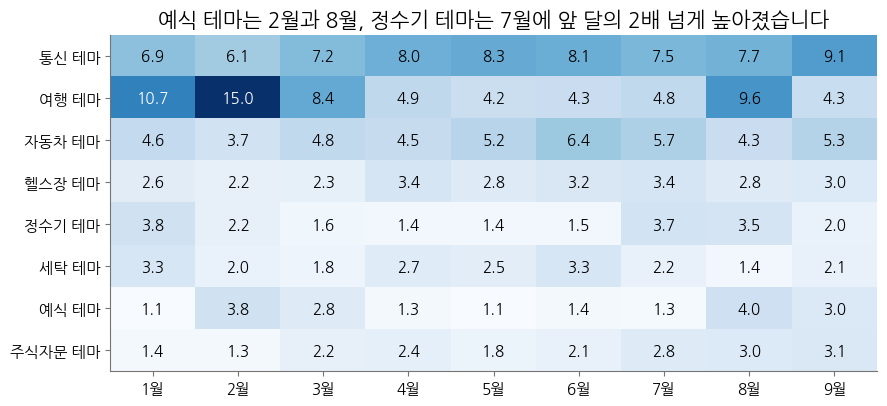

In [3]:
# 자료 준비 · 그림 1: 테마 8개의 1～9월 비율(%). 기타는 분모에만 포함하고 그림에서는 뺍니다
show = 100 * SHARE.drop(index="기타")
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.imshow(show.to_numpy(), cmap="Blues", aspect="auto")
for (i, j), v in np.ndenumerate(show.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", color="white" if v > 10 else "black")
ax.set_xticks(range(9), [f"{m}월" for m in show.columns])
ax.set_yticks(range(len(show)), [SHORT[t] for t in show.index])
ax.set_title("예식 테마는 2월과 8월, 정수기 테마는 7월에 앞 달의 2배 넘게 높아졌습니다")
plt.show()

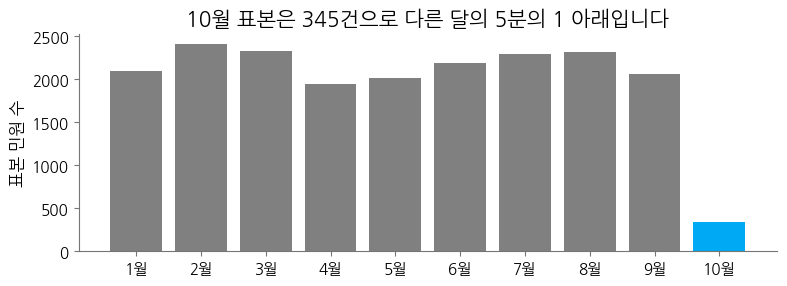

In [4]:
# 자료 준비 · 그림 2: 월별 표본 수(하늘색은 10월)
n_all = SAMPLE["month"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar([f"{m}월" for m in n_all.index], n_all.values, color=["#00A9F4" if m == 10 else "gray" for m in n_all.index])
ax.set_ylabel("표본 민원 수")
ax.set_title("10월 표본은 345건으로 다른 달의 5분의 1 아래입니다")
plt.show()

기타를 분모에서 빼면 어떻게 될까요?

- 100건 가운데 한 테마가 4건 · 다른 테마가 36건 · 기타가 60건이면, 기타를 뺀 그 테마의 비율은 4 ÷ 40 = 10% 입니다.
- 기타가 70건이고 다른 테마가 26건이면 4 ÷ 30 ≈ 13% 입니다.

테마 건수가 그대로여도 비율이 오르므로, 분모는 기타까지 포함한 그 달 표본 전체로 정합니다.

10월은 자료가 중간에 끊긴 잘린 달이라 테마 비율표는 1～9월로 만듭니다.

## 단계 1 분모와 두 달 차이

- **할 일**: 표 1 의 번호로, 두 달 차이의 95% 구간이 0 을 포함하지 않는 테마는 `MY_BEYOND`, 원문을 확인할 달이 있는 테마는 `MY_CHECK` 에 적습니다.
- **연습하는 것**: 두 달 차이의 95% 구간으로 비율이 실제로 바뀐 테마를 찾는 법

테마 비율이 앞 달보다 높아진 달은 모두 원문을 읽어야 할까요? 아닙니다. 앞 달보다 높아졌어도 표본 변동만으로 생긴 차이일 수 있습니다.

- **테마 비율**은 그 달 표본 가운데 그 테마에 속한 민원의 비율이고, 분모는 기타까지 포함한 그 달 표본 전체입니다.
- **두 달 차이의 95% 구간**은 표본 변동을 감안할 때 두 달 비율의 차이가 있을 만한 범위입니다. 0 을 포함하면 표본 변동만으로도 생길 수 있는 차이입니다.
- **원문을 확인할 달**은 앞 달보다 비율이 1.5배 이상 오르고, 두 달 차이의 95% 구간이 0 을 포함하지 않는 달입니다.

```text
각 달 비율의 오차 한계 = 1.96 × √(그 달 비율 × (1 − 그 달 비율) ÷ 그 달 표본 수)
두 달 차이            = 그 달 비율 − 앞 달 비율
두 달 차이의 오차 한계 = 1.96 × √(앞 달 비율 × (1 − 앞 달 비율) ÷ 앞 달 표본 수 + 그 달 비율 × (1 − 그 달 비율) ÷ 그 달 표본 수)
95% 구간              = 두 달 차이 ± 두 달 차이의 오차 한계
```

건수가 많으면 작은 차이도 구간이 0 을 포함하지 않아, 1.5배라는 크기 기준을 함께 씁니다. 이 실습의 비율은 민원 50만 건에서 추출한 표본 2만 건으로 구한 값입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/8f/NYW-confidence-interval.svg" alt="가로로 늘어선 파란 세로 선분 50개와 그 가운데를 지나는 분홍 점선 μ. 선분 대부분이 점선을 가로지르고 몇 개는 점선 위나 아래에서 끝난다" width="560" height="230"/>
<p align="center"><em>▲ 같은 모집단에서 표본을 50번 추출해 구한 95% 구간 50개다. 대부분은 분홍 점선의 참값 μ 를 가로지르고, 몇 개는 참값 μ 를 포함하지 않는다. 표 1 의 비율도 표본 하나로 구한 값이라 다른 표본이면 조금 다르게 나온다 (출처: Wikimedia Commons, NYW-confidence-interval.svg, Tsyplakov, Public domain)</em></p>

표 1 은 테마 4개마다 비율이 오른 달을 그 앞 달과 비교합니다. 4쌍에는 한 조건만 만족하는 쌍, 둘 다 만족하지 않는 쌍, 둘 다 만족하는 쌍이 모두 있습니다. 어느 테마가 어느 경우인지는 표 1 을 보고 직접 해 보기에서 고릅니다. 예식 8월은 결론에서 같은 두 조건으로 확인합니다.

In [5]:
# 단계 1: 테마 4개의 두 달 비율 · 앞 달 대비 배수 · 두 달 차이의 95% 구간(분모는 그 달 표본 전체)
PAIRS = [("헬스장·운동 강습 중도 해지 환불", 3, 4), ("자동차·오토바이 구입·수리·렌트·보험", 5, 6),
         ("정수기 렌탈 민원", 6, 7), ("예식 취소·위약금", 1, 2)]
GAP = []
for no, (theme, m0, m1) in enumerate(PAIRS, 1):
    p0, p1 = SHARE.loc[theme, m0], SHARE.loc[theme, m1]
    v0, v1 = p0 * (1 - p0) / N_MONTH[m0], p1 * (1 - p1) / N_MONTH[m1]      # 두 달 각각의 분산
    moe = 1.96 * np.sqrt(v0 + v1)                                          # 두 달 차이의 오차 한계
    GAP.append({"no": no, "name": f"{SHORT[theme]} {m0}월→{m1}월", "m0": m0, "m1": m1,
                "p0": 100 * p0, "p1": 100 * p1, "ratio": p1 / p0, "diff": 100 * (p1 - p0),
                "lo": 100 * (p1 - p0 - moe), "hi": 100 * (p1 - p0 + moe),
                "moe0": 100 * 1.96 * np.sqrt(v0), "moe1": 100 * 1.96 * np.sqrt(v1)})
print("표 1 · 테마 4개의 두 달 비율과 두 달 차이의 95% 구간 (%, %p)")
for g in GAP:
    print(f"{g['no']}. {g['name']}: {fmt(g['p0'], 2)}% → {fmt(g['p1'], 2)}% · 앞 달 대비 {g['ratio']:.3f}배"
          f" · 차이 {signed(g['diff'], 2)}%p · 95% 구간 {fmt(g['lo'], 2)}～{fmt(g['hi'], 2)}%p")
    print(f"   각 달 비율의 오차 한계: {g['m0']}월 ±{fmt(g['moe0'], 2)}%p · {g['m1']}월 ±{fmt(g['moe1'], 2)}%p")
print("앞 달 대비 배수는 반올림하기 전의 그 달 비율을 앞 달 비율로 나눈 값입니다")
w = "예식 취소·위약금"
print(f"예식 테마의 건수와 분모: 1월 {COUNTS.loc[w, 1]}건({N_MONTH[1]:,}건 가운데) → 2월 {COUNTS.loc[w, 2]}건({N_MONTH[2]:,}건 가운데)"
      f" · 건수 {COUNTS.loc[w, 2] / COUNTS.loc[w, 1]:.2f}배, 분모 {N_MONTH[2] / N_MONTH[1]:.2f}배")

표 1 · 테마 4개의 두 달 비율과 두 달 차이의 95% 구간 (%, %p)
1. 헬스장 테마 3월→4월: 2.27% → 3.40% · 앞 달 대비 1.498배 · 차이 +1.13%p · 95% 구간 0.12～2.14%p
   각 달 비율의 오차 한계: 3월 ±0.60%p · 4월 ±0.81%p
2. 자동차 테마 5월→6월: 5.20% → 6.35% · 앞 달 대비 1.222배 · 차이 +1.15%p · 95% 구간 −0.26～2.56%p
   각 달 비율의 오차 한계: 5월 ±0.97%p · 6월 ±1.02%p
3. 정수기 테마 6월→7월: 1.51% → 3.70% · 앞 달 대비 2.454배 · 차이 +2.19%p · 95% 구간 1.27～3.12%p
   각 달 비율의 오차 한계: 6월 ±0.51%p · 7월 ±0.77%p
4. 예식 테마 1월→2월: 1.10% → 3.82% · 앞 달 대비 3.474배 · 차이 +2.72%p · 95% 구간 1.83～3.60%p
   각 달 비율의 오차 한계: 1월 ±0.45%p · 2월 ±0.77%p
앞 달 대비 배수는 반올림하기 전의 그 달 비율을 앞 달 비율로 나눈 값입니다
예식 테마의 건수와 분모: 1월 23건(2,093건 가운데) → 2월 92건(2,410건 가운데) · 건수 4.00배, 분모 1.15배


예식 테마는 1월 → 2월에 건수가 4배가 되는 동안 분모는 1.15배 늘었습니다. 비율이 오른 것은 분모가 줄어서가 아니라 건수가 늘었기 때문입니다.

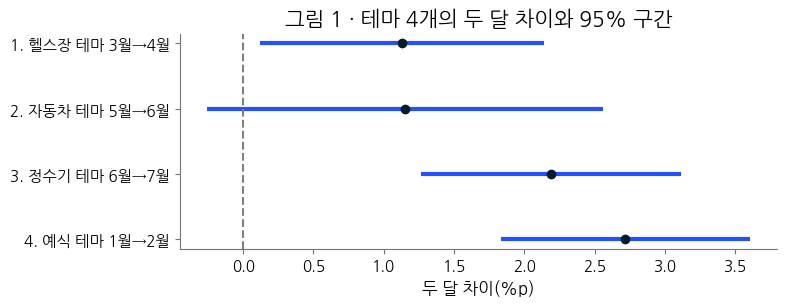

In [6]:
# 단계 1 · 그림 1: 두 달 차이(점)와 95% 구간(가로선). 점선은 차이 0
fig, ax = plt.subplots(figsize=(8, 3.2))
for g in GAP:
    ax.hlines(g["no"], g["lo"], g["hi"], color="#2251FF", linewidth=3)
    ax.plot(g["diff"], g["no"], "o", color="#051C2C")
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks([g["no"] for g in GAP], [f"{g['no']}. {g['name']}" for g in GAP])
ax.invert_yaxis()
ax.set_xlabel("두 달 차이(%p)")
ax.set_title("그림 1 · 테마 4개의 두 달 차이와 95% 구간")
plt.show()

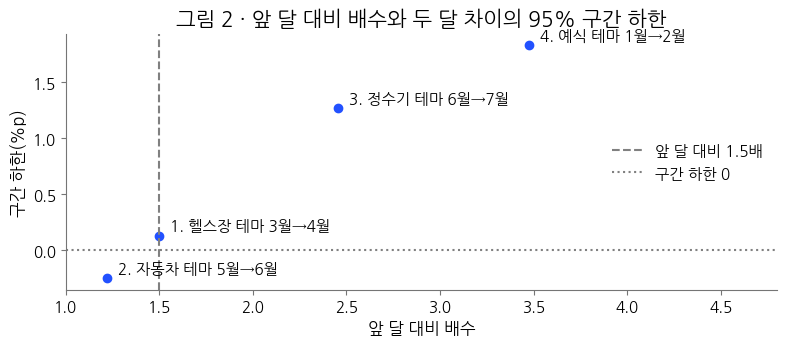

In [7]:
# 단계 1 · 그림 2: 앞 달 대비 배수(가로)와 두 달 차이의 95% 구간 하한(세로)
fig, ax = plt.subplots(figsize=(8, 3.6))
for g in GAP:
    ax.plot(g["ratio"], g["lo"], "o", color="#2251FF")
    ax.annotate(f"{g['no']}. {g['name']}", (g["ratio"], g["lo"]), textcoords="offset points", xytext=(8, 4))
ax.axvline(1.5, color="gray", linestyle="--", label="앞 달 대비 1.5배")
ax.axhline(0, color="gray", linestyle=":", label="구간 하한 0")
ax.set(xlabel="앞 달 대비 배수", ylabel="구간 하한(%p)", xlim=(1, 4.8))
ax.legend(frameon=False, loc="center right")
ax.set_title("그림 2 · 앞 달 대비 배수와 두 달 차이의 95% 구간 하한")
plt.show()

**직접 해 보기: 두 달 차이의 95% 구간과 원문을 확인할 달**

표 1 의 번호로 적습니다. 해당하는 번호가 없으면 빈 목록 `[]` 입니다.

- `MY_BEYOND`: 두 달 차이의 95% 구간이 0 을 포함하지 않는 테마의 번호 목록
- `MY_CHECK`: 원문을 확인할 달이 있는 테마의 번호 목록
- 적는 방법: `MY_BEYOND = [○, ○, …]`(○ 하나가 표 1 의 번호 하나)

In [8]:
# 단계 1 · 직접 해 보기: 표 1 의 번호 목록(따옴표 없이 대괄호 안에)
MY_BEYOND = [1, 3, 4]
MY_CHECK =[3, 4]

In [9]:
# 단계 1 · 확인 셀: MY_BEYOND · MY_CHECK 를 표 1 의 두 조건과 비교합니다
def parse_rows(rows, name):
    if isinstance(rows, (int, np.integer)) and not isinstance(rows, bool):
        rows = [rows]
    if not isinstance(rows, (list, tuple, set)) or any(isinstance(r, bool) or not isinstance(r, (int, np.integer)) for r in rows):
        return None, f"고칠 것: {name} 는 따옴표 없이 표 1 의 번호(정수)를 대괄호 안에 적습니다"
    extra = sorted(set(int(r) for r in rows) - {1, 2, 3, 4})
    if extra:
        return None, f"고칠 것: {name} 에 표 1 에 없는 번호({', '.join(map(str, extra))})가 있습니다. 번호는 1～4 입니다"
    return sorted(set(int(r) for r in rows)), ""


def row_note(g):
    ci = "0 을 포함하지 않음" if g["lo"] > 0 or g["hi"] < 0 else "0 을 포함"
    size = "1.5배 이상" if g["ratio"] >= 1.5 else "1.5배에 못 미침"
    return f"  {g['no']}. {g['name']}: 구간 {fmt(g['lo'], 2)}～{fmt(g['hi'], 2)}%p, {ci} · {g['ratio']:.3f}배, {size}"


def check_rows(beyond, check):
    if beyond is None and check is None:
        print("아직 채우지 않았습니다. 위 셀의 MY_BEYOND · MY_CHECK 를 채운 뒤 다시 실행합니다")
        return
    if "GAP" not in globals():
        print("단계 1 의 첫 셀(표 1)을 먼저 실행한 뒤 이 셀을 다시 실행합니다")
        return
    right = {"MY_BEYOND": [g["no"] for g in GAP if g["lo"] > 0 or g["hi"] < 0],
             "MY_CHECK": [g["no"] for g in GAP if g["ratio"] >= 1.5 and g["lo"] > 0]}
    what = {"MY_BEYOND": "두 달 차이의 95% 구간이 0 을 포함하지 않는 테마는", "MY_CHECK": "원문을 확인할 달이 있는 테마는"}
    checked = 0
    for name, val in (("MY_BEYOND", beyond), ("MY_CHECK", check)):
        rows, msg = (None, f"{name} 는 아직 채우지 않았습니다") if val is None else parse_rows(val, name)
        if rows is None:
            print(msg)
            continue
        checked += 1
        word = "맞았습니다" if rows == right[name] else "아직 다릅니다"
        print(f"{name}: {word}. {what[name]} {' · '.join(map(str, right[name]))}번입니다")
    if not checked:
        return
    for g in GAP:
        print(row_note(g))
    h = GAP[0]
    print(f"헬스장 테마 4월은 {fmt(h['p1'], 2)} ÷ {fmt(h['p0'], 2)} ≈ {rnd(h['p1'], 2) / rnd(h['p0'], 2):.3f}배라,"
          " 구간이 0 을 포함하지 않지만 원문을 확인할 달은 아닙니다")


check_rows(globals().get("MY_BEYOND"), globals().get("MY_CHECK"))

MY_BEYOND: 맞았습니다. 두 달 차이의 95% 구간이 0 을 포함하지 않는 테마는 1 · 3 · 4번입니다
MY_CHECK: 맞았습니다. 원문을 확인할 달이 있는 테마는 3 · 4번입니다
  1. 헬스장 테마 3월→4월: 구간 0.12～2.14%p, 0 을 포함하지 않음 · 1.498배, 1.5배에 못 미침
  2. 자동차 테마 5월→6월: 구간 −0.26～2.56%p, 0 을 포함 · 1.222배, 1.5배에 못 미침
  3. 정수기 테마 6월→7월: 구간 1.27～3.12%p, 0 을 포함하지 않음 · 2.454배, 1.5배 이상
  4. 예식 테마 1월→2월: 구간 1.83～3.60%p, 0 을 포함하지 않음 · 3.474배, 1.5배 이상
헬스장 테마 4월은 3.40 ÷ 2.27 ≈ 1.498배라, 구간이 0 을 포함하지 않지만 원문을 확인할 달은 아닙니다


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_BEYOND = [1, 3, 4]` · `MY_CHECK = [3, 4]`

- 2번 자동차 테마는 차이 +1.15%p 가 1번 헬스장 테마의 +1.13%p 와 비슷하지만, 비율이 5～6% 대라 구간이 −0.26～2.56%p 로 넓어 0 을 포함합니다.
- 1번 헬스장 테마 4월은 3.40 ÷ 2.27 ≈ 1.498배로 1.5배에 조금 못 미칩니다. 그림 2 에서 점이 1.5배 점선의 바로 왼쪽에 있습니다.
- 3번 정수기 테마 7월(2.454배)과 4번 예식 테마 2월(3.474배)이 원문을 확인할 달입니다.

</details>

> **[문제] 두 달 차이의 95% 구간이 0 을 포함하는가**
>
> 「표 1 · 테마 4개의 두 달 비율과 두 달 차이의 95% 구간 (%, %p)」과 「그림 1 · 테마 4개의 두 달 차이와 95% 구간」에서, 헬스장 테마 3월→4월과 자동차 테마 5월→6월 가운데 표본 변동만으로는 생기기 어려운 증가는 어느 쪽일까요?
>
> 1. 둘 다: 두 차이가 모두 0 보다 크다
> 2. 자동차 5월→6월만: 차이가 조금 더 크다
> 3. 헬스장 3월→4월만: 차이의 구간이 0 을 포함하지 않는다

> **[문제] 원문을 확인할 달**
>
> 「표 1 · 테마 4개의 두 달 비율과 두 달 차이의 95% 구간 (%, %p)」에서 원문을 확인할 달은 어느 달일까요? 원문을 확인할 달은 앞 달보다 비율이 1.5배 이상 오르고, 두 달 차이의 95% 구간이 0 을 포함하지 않는 달입니다.
>
> 1. 정수기 테마 7월과 예식 테마 2월
> 2. 차이가 가장 큰 예식 테마 2월만
> 3. 구간이 0 을 포함하지 않는 3개 모두

## 단계 2 달력과 잘린 달

- **할 일**: 접수가 이어진 마지막 날을 `MY_LAST_DAY`, 10-01 부터 그 날까지의 영업일당 건수를 `MY_BIZ_RATE` 에 적습니다.
- **연습하는 것**: 영업일 수가 다르거나 자료가 중간에 잘려 건수가 달라진 달을 알아보는 법

전임 담당자는 월 건수 막대를 보고 「10월 민원 82% 감소, 추석 이후 민원 안정」이라고 썼습니다. 10월 월 건수가 9월보다 81.8% 적으면 10월 민원이 줄어든 것일까요? 영업일 수와 일별 건수로 답을 찾습니다.

- **영업일**은 월요일～금요일 가운데 공휴일이 아닌 날입니다. 쉬는 날에는 접수가 거의 없습니다.
- **영업일당 건수**는 그 기간 접수 건수를 그 기간 영업일 수로 나눈 값입니다. 분자에는 주말 · 공휴일에 접수된 민원도 포함합니다.
- **잘린 달**은 자료 수집이 그 달 중간에서 끊겨, 그 달 민원의 일부만 자료에 있는 달입니다.
- **끊긴 날**은 일별 건수가 9월 영업일당 건수의 절반 아래로 떨어진 뒤 다시 오르지 않는 첫 영업일입니다. **접수가 이어진 마지막 날**은 끊긴 날 바로 앞의 영업일입니다.

> **[예측] 10월의 영업일당 건수를 10-01 부터 접수가 이어진 마지막 날까지로 계산하면, 9월과 비교해 어떨까요?**
>
> 1. 9월의 절반 아래다
> 2. 9월과 비슷하다
> 3. 9월보다 크게 많다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

In [10]:
# 단계 2: 9월과 10월의 월 건수와 영업일(원자료 접수일자)
MONTHLY = DAILY.groupby(DAILY.index.month).sum()                     # 달 → 월 건수
CAL = pd.date_range("2020-01-01", "2020-10-31")
BIZ = pd.Series(is_biz(CAL), index=CAL).groupby(CAL.month).sum()     # 달 → 그 달 영업일 수
SEP_RATE = MONTHLY[9] / BIZ[9]                                       # 9월 영업일당 건수
print("표 2 · 9월과 10월의 월 건수와 영업일 (원자료 접수일자)")
print(f"9월: 월 건수 {MONTHLY[9]:,} · 영업일 {BIZ[9]}일 · 영업일당 건수 {fmt(SEP_RATE, 1)}")
print(f"10월: 월 건수 {MONTHLY[10]:,} · 영업일 {BIZ[10]}일 · 접수일자 10-01～{DAILY.index.max():%m-%d}")
print(f"10월 월 건수는 9월보다 {fmt(100 * (1 - MONTHLY[10] / MONTHLY[9]), 1)}% 적습니다")

표 2 · 9월과 10월의 월 건수와 영업일 (원자료 접수일자)
9월: 월 건수 51,615 · 영업일 21일 · 영업일당 건수 2,457.9
10월: 월 건수 9,371 · 영업일 19일 · 접수일자 10-01～10-17
10월 월 건수는 9월보다 81.8% 적습니다


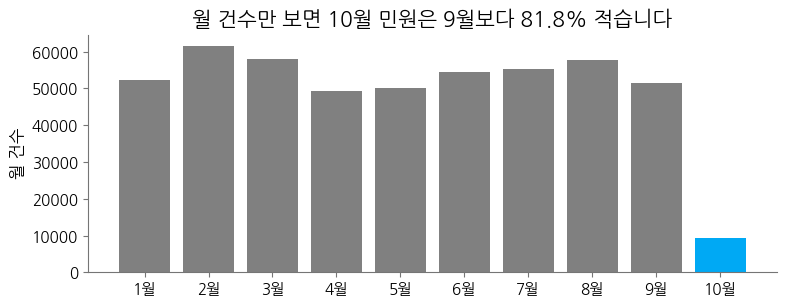

In [11]:
# 단계 2 · 그림 1: 1～10월 월 건수(하늘색은 10월)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar([f"{m}월" for m in MONTHLY.index], MONTHLY.values, color=["#00A9F4" if m == 10 else "gray" for m in MONTHLY.index])
ax.set_ylabel("월 건수")
ax.set_title("월 건수만 보면 10월 민원은 9월보다 81.8% 적습니다")
plt.show()

In [12]:
# 단계 2: 10월 일별 접수 건수와 10월 1일부터 더한 누적 건수(원자료 접수일자)
OCT = DAILY["2020-10-01":]
WEEK = "월화수목금토일"
kind = np.where(OCT.index.isin(HOLIDAYS_2020), "공휴일", np.where(OCT.index.weekday >= 5, "주말", "영업일"))
cum, cum_biz = OCT.cumsum(), is_biz(OCT.index).cumsum()
print("표 3 · 10월 일별 접수 건수와 10월 1일부터 더한 누적 건수 (원자료 접수일자)")
for d, k, n, c, b in zip(OCT.index, kind, OCT.values, cum.values, cum_biz):
    print(f"{d:%m-%d} {WEEK[d.weekday()]} · {k} · {n:,}건 · 누적 {c:,}건 · 누적 영업일 {b}일")
HALF = SEP_RATE / 2
print(f"9월 영업일당 건수 {fmt(SEP_RATE, 1)}건의 절반: {fmt(HALF, 1)}건")

표 3 · 10월 일별 접수 건수와 10월 1일부터 더한 누적 건수 (원자료 접수일자)
10-01 목 · 공휴일 · 24건 · 누적 24건 · 누적 영업일 0일
10-02 금 · 공휴일 · 30건 · 누적 54건 · 누적 영업일 0일
10-03 토 · 주말 · 23건 · 누적 77건 · 누적 영업일 0일
10-04 일 · 주말 · 30건 · 누적 107건 · 누적 영업일 0일
10-05 월 · 영업일 · 2,479건 · 누적 2,586건 · 누적 영업일 1일
10-06 화 · 영업일 · 2,224건 · 누적 4,810건 · 누적 영업일 2일
10-07 수 · 영업일 · 2,224건 · 누적 7,034건 · 누적 영업일 3일
10-08 목 · 영업일 · 2,157건 · 누적 9,191건 · 누적 영업일 4일
10-09 금 · 공휴일 · 62건 · 누적 9,253건 · 누적 영업일 4일
10-10 토 · 주말 · 62건 · 누적 9,315건 · 누적 영업일 4일
10-11 일 · 주말 · 10건 · 누적 9,325건 · 누적 영업일 4일
10-12 월 · 영업일 · 33건 · 누적 9,358건 · 누적 영업일 5일
10-13 화 · 영업일 · 3건 · 누적 9,361건 · 누적 영업일 6일
10-14 수 · 영업일 · 2건 · 누적 9,363건 · 누적 영업일 7일
10-15 목 · 영업일 · 4건 · 누적 9,367건 · 누적 영업일 8일
10-16 금 · 영업일 · 3건 · 누적 9,370건 · 누적 영업일 9일
10-17 토 · 주말 · 1건 · 누적 9,371건 · 누적 영업일 9일
9월 영업일당 건수 2,457.9건의 절반: 1,228.9건


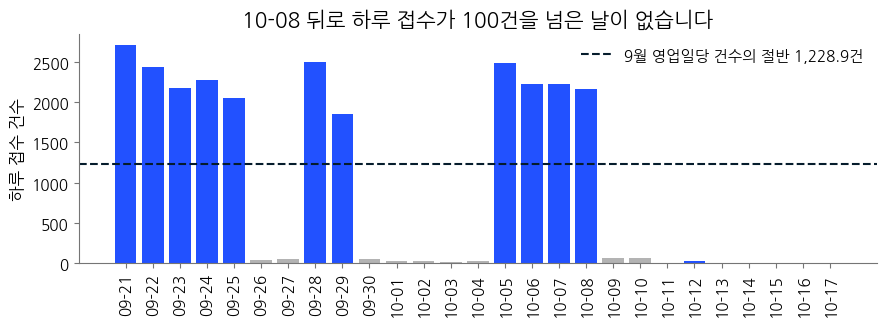

In [13]:
# 단계 2 · 그림 2: 09-21～10-17 일별 접수 건수(파랑은 영업일, 회색은 주말 · 공휴일)
win = DAILY["2020-09-21":"2020-10-17"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(win.index.strftime("%m-%d"), win.values, color=["#2251FF" if b else "#B3B3B3" for b in is_biz(win.index)])
ax.axhline(HALF, color="#051C2C", linestyle="--", label=f"9월 영업일당 건수의 절반 {fmt(HALF, 1)}건")
ax.tick_params(axis="x", rotation=90)
ax.set_ylabel("하루 접수 건수")
ax.legend(frameon=False)
ax.set_title("10-08 뒤로 하루 접수가 100건을 넘은 날이 없습니다")
plt.show()

답은 둘째 보기 「9월과 비슷하다」입니다. 위 그림에서 추석 연휴 바로 뒤인 10-05～10-08 에는 하루 2,000건 넘게 들어왔습니다.

- 10월 월 건수가 9월보다 81.8% 적은 것은 자료가 끊긴 뒤의 접수가 파일에 거의 없기 때문입니다.
- 81.8% 감소는 영업일 수만으로는 설명되지 않습니다. 건수가 영업일 수에 비례한다면 19 ÷ 21 ≈ 0.90 이라, 감소는 약 10% 에 그칩니다.

**직접 해 보기: 접수가 이어진 마지막 날과 영업일당 건수**

- `MY_LAST_DAY`: 표 3 과 위 그림으로 찾은 접수가 이어진 마지막 날(월-일 형식의 문자열)
- `MY_BIZ_RATE`: 10-01 부터 그 날까지의 영업일당 건수(건, 소수 첫째 자리, 따옴표 없이 숫자)
- 적는 방법: `MY_LAST_DAY = "○○-○○"`

In [14]:
# 단계 2 · 직접 해 보기: 접수가 이어진 마지막 날("월-일") · 10-01 부터 그 날까지의 영업일당 건수(숫자)
MY_LAST_DAY = "10-08"
MY_BIZ_RATE = 2297.8

In [15]:
# 단계 2 · 확인 셀: MY_LAST_DAY · MY_BIZ_RATE 를 일별 건수로 구한 값과 비교합니다
def parse_day(text):
    m = re.fullmatch(r"\s*(?:2020-)?(\d{1,2})[-./](\d{1,2})\s*", text) if isinstance(text, str) else None
    try:
        return pd.Timestamp(2020, int(m.group(1)), int(m.group(2))) if m else None
    except ValueError:
        return None


def check_calendar(last_day, rate):
    if last_day is None and rate is None:
        print("아직 채우지 않았습니다. 위 셀의 MY_LAST_DAY · MY_BIZ_RATE 를 채운 뒤 다시 실행합니다")
        return
    if "HALF" not in globals():
        print("단계 2 의 표 2 · 표 3 셀을 먼저 실행한 뒤 이 셀을 다시 실행합니다")
        return
    biz = DAILY[is_biz(DAILY.index)]
    cut = next(d for d in biz.index if (biz[d:] < HALF).all())               # 끊긴 날
    last = biz.index[biz.index.get_loc(cut) - 1]                             # 접수가 이어진 마지막 날
    head = DAILY["2020-10-01":last]
    right = head.sum() / is_biz(head.index).sum()
    day, num = parse_day(last_day), isinstance(rate, (int, float)) and not isinstance(rate, bool)
    if day is None:
        print("MY_LAST_DAY 는 아직 채우지 않았습니다" if last_day is None else
              '고칠 것: MY_LAST_DAY 는 따옴표 안에 월-일 형식("○○-○○")으로 적습니다')
    elif day == last:
        print(f"MY_LAST_DAY: 맞았습니다. 끊긴 날은 하루 접수가 9월 영업일당 건수의 절반 {fmt(HALF, 1)}건 아래로 떨어진 뒤"
              f" 다시 오르지 않는 첫 영업일 {cut:%m-%d} 입니다. 접수가 이어진 마지막 날은 그 앞 영업일 {last:%m-%d} 입니다")
    else:
        why = ("끊긴 날입니다. 접수가 이어진 마지막 날은 끊긴 날 바로 앞의 영업일입니다" if day == cut else
               "파일에 있는 마지막 접수일입니다. 그 전에 하루 접수가 9월 영업일당 건수의 절반 아래로 떨어진 영업일을 찾습니다"
               if day == DAILY.index.max() else
               "영업일이 아닙니다(주말 · 공휴일). 마지막 영업일을 찾습니다" if not is_biz(pd.DatetimeIndex([day]))[0] else
               "끊긴 날 바로 앞의 영업일이 아닙니다. 9월 영업일당 건수의 절반 아래로 떨어진 뒤 다시 오르지 않는 첫 영업일부터 찾습니다")
        print(f"MY_LAST_DAY: 아직 다릅니다. MY_LAST_DAY 의 날짜는 {why}")
    traps = {"영업일에 들어온 건수만 더했습니다. 분자에는 주말 · 공휴일 접수분도 포함합니다": head[is_biz(head.index)].mean(),
             f"날 수 {len(head)}일로 나눴습니다. 분모는 영업일 수입니다": head.mean(),
             "10-01 · 10-02 는 평일이지만 추석 연휴라 영업일이 아닙니다": head.sum() / (head.index.weekday < 5).sum(),
             "끊긴 뒤의 날까지 더했습니다. 접수가 이어진 마지막 날까지만 계산합니다": OCT.sum() / is_biz(OCT.index).sum(),
             f"10월 전체 건수를 10월 영업일 {BIZ[10]}일로 나눴습니다. 끊긴 뒤의 영업일은 분모에서 뺍니다": OCT.sum() / BIZ[10],
             "9월의 영업일당 건수입니다. 10-01 부터 접수가 이어진 마지막 날까지로 구합니다": SEP_RATE}
    if not num:
        print("MY_BIZ_RATE 는 아직 채우지 않았습니다" if rate is None else "고칠 것: MY_BIZ_RATE 는 따옴표 없이 숫자로 적습니다")
    elif abs(rate - right) <= 0.06:
        print(f"MY_BIZ_RATE: 맞았습니다. 10-01～{last:%m-%d} 의 {head.sum():,}건 ÷ 영업일 {is_biz(head.index).sum()}일"
              f" = {fmt(right, 1)}건입니다")
    else:
        hit = next((msg for msg, v in traps.items() if abs(rate - rnd(v, 1)) <= 0.06), None)
        near = ("소수 첫째 자리까지 적었는지 확인합니다" if abs(rate - right) < 1 else
                "10-01 부터 접수가 이어진 마지막 날까지의 건수를 그 기간 영업일 수로 나눕니다")
        print(f"MY_BIZ_RATE: 아직 다릅니다. {hit or near}")
    if day is not None or num:
        print(f"「10월 민원 82% 감소」는 틀린 결론입니다. 접수가 {last:%m-%d} 을 끝으로 끊겼고,"
              f" 그날까지의 영업일당 건수는 9월의 {right / SEP_RATE:.3f}배입니다")


check_calendar(globals().get("MY_LAST_DAY"), globals().get("MY_BIZ_RATE"))

MY_LAST_DAY: 맞았습니다. 끊긴 날은 하루 접수가 9월 영업일당 건수의 절반 1,228.9건 아래로 떨어진 뒤 다시 오르지 않는 첫 영업일 10-12 입니다. 접수가 이어진 마지막 날은 그 앞 영업일 10-08 입니다
MY_BIZ_RATE: 맞았습니다. 10-01～10-08 의 9,191건 ÷ 영업일 4일 = 2,297.8건입니다
「10월 민원 82% 감소」는 틀린 결론입니다. 접수가 10-08 을 끝으로 끊겼고, 그날까지의 영업일당 건수는 9월의 0.935배입니다


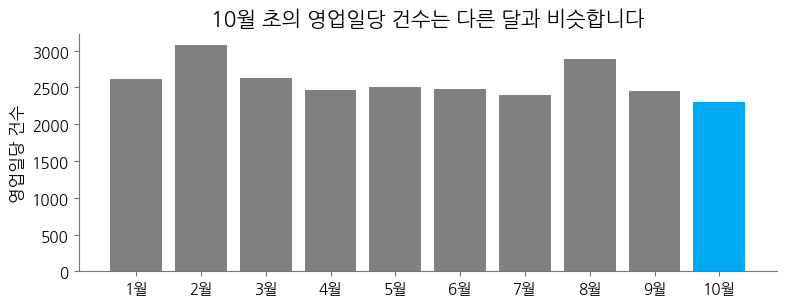

In [16]:
# 단계 2 · 그림 3: 달마다 영업일당 건수(10월은 10-01 부터 접수가 이어진 마지막 날까지)
biz = DAILY[is_biz(DAILY.index)]
cut = next(d for d in biz.index if (biz[d:] < HALF).all())                 # 끊긴 날
head = DAILY["2020-10-01":biz.index[biz.index.get_loc(cut) - 1]]            # 10-01 부터 접수가 이어진 마지막 날까지
rate = list(MONTHLY.loc[1:9] / BIZ.loc[1:9]) + [head.sum() / is_biz(head.index).sum()]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar([f"{m}월" for m in range(1, 11)], rate, color=["gray"] * 9 + ["#00A9F4"])
ax.set_ylabel("영업일당 건수")
ax.set_title("10월 초의 영업일당 건수는 다른 달과 비슷합니다")
plt.show()

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_LAST_DAY = "10-08"` · `MY_BIZ_RATE = 2297.8`

- 10-12(월)는 영업일인데 33건이고, 그 뒤로 하루 접수가 9월 영업일당 건수의 절반 1,228.9건 위로 다시 오르지 않습니다. 10-12 가 끊긴 날이고, 그 앞 영업일 10-08 이 접수가 이어진 마지막 날입니다.
- 10-01～10-08 의 누적 9,191건을 영업일 4일(10-05～10-08)로 나누면 2,297.8건입니다. 추석 연휴 10-01 · 10-02 와 주말에 들어온 민원도 분자에 포함합니다.
- 10-09 부터 10-17 까지 9일을 모두 합쳐도 180건입니다. 10월은 잘린 달이라 테마 비율표에서 뺍니다.

</details>

## 단계 3 원문과 한 판매처 집중

- **할 일**: 한 판매처 집중인지를 `MY_CONCENTRATED` 에 True · False 로, 그렇게 본 이유 한 문장을 `MY_WHY` 에 적습니다.
- **연습하는 것**: 원문과 품목으로 한 판매처의 민원이 비율을 바꿨는지 확인하는 법

예식 테마 2월은 1월의 3.474배이고 두 달 차이의 95% 구간도 0 을 포함하지 않아, 원문을 확인할 달입니다. 늘어난 민원은 한 판매처의 민원일까요? 드릴다운으로 알아봅니다.

**드릴다운(drill-down)** 은 월별 합계에서 민원 한 건 한 건의 원문으로 내려가 무엇이 늘었는지 확인하는 일입니다.

- ① 품목으로 나눠 무엇이 늘었는지 봅니다. 품목은 상품의 종류라, 한 품목에 여러 판매처의 민원이 있습니다.
- ② 원문을 무작위로 10건 읽고, 같은 상호가 여러 번 나오는지 봅니다. 이 자료에는 판매처를 따로 기록한 열이 없어, 판매처는 제목에 있는 상호로 찾습니다.
- ③ 제목에 상호가 나온 판매처는 그 달 그 테마의 민원 전체에서 비중 s 를 구합니다.
- ④ s 가 0.5 를 넘으면 판매처 표시 열에 그 판매처를 기록하고, 그 판매처를 뺀 증가가 있는지 다시 확인합니다. **판매처 표시 열**은 민원마다 그 판매처의 민원이면 판매처 이름을, 아니면 「없음」을 기록하는 열입니다.

```text
s = 그 판매처 상호가 제목에 있는 민원 수 ÷ 그 달 그 테마의 민원 수
```

**한 판매처 집중**은 한 판매처의 민원이 그 달 그 테마 민원의 절반을 넘게 차지한 일입니다. s 가 0.5 를 넘으면 한 판매처 집중입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/46/OLAP_drill_up%26down.png" alt="품목군 × 지역 × 연도 합계 표에서 파란 행 하나를 골라 오른쪽에서 세 세부 품목으로 나눈 그림" width="900" height="326"/>
<p align="center"><em>▲ 합계 표에서 한 행을 골라 세부로 내려가는 드릴다운이다. 왼쪽 표의 파란 행(야외 보호 장비)이 오른쪽에서 품목 3개로 나뉜다. 표 4 와 표 5 는 예식 테마 2월을 품목과 원문 제목까지 내려가 확인한 결과다 (출처: Wikimedia Commons 「OLAP drill up&amp;down.png」, Infopedian, CC BY-SA 4.0)</em></p>

In [17]:
# 단계 3: 예식 테마 1월과 2월 민원의 품목 상위 3(비중의 분모는 그 달 예식 테마 민원 수)
WEDDING = "예식 취소·위약금"
WED = SAMPLE[(SAMPLE["theme"] == WEDDING) & SAMPLE["month"].isin([1, 2])]
ITEMS = {}
print("표 4 · 예식 테마 1월과 2월 민원의 품목 상위 3 (건, 비중)")
for m in (1, 2):
    docs = WED[WED["month"] == m]
    ITEMS[m] = docs["품목명"].value_counts().sort_index().sort_values(ascending=False, kind="stable")   # 건수가 같으면 이름 차례
    top = " · ".join(f"{item} {k}건({rnd(k / len(docs), 3):.3f})" for item, k in ITEMS[m].head(3).items())
    print(f"{m}월({len(docs)}건): {top}")

표 4 · 예식 테마 1월과 2월 민원의 품목 상위 3 (건, 비중)
1월(23건): 결혼준비대행서비스 6건(0.261) · 국내결혼중개 5건(0.217) · 사진촬영 5건(0.217)
2월(92건): 예식서비스 63건(0.685) · 결혼준비대행서비스 11건(0.120) · 국내결혼중개 7건(0.076)


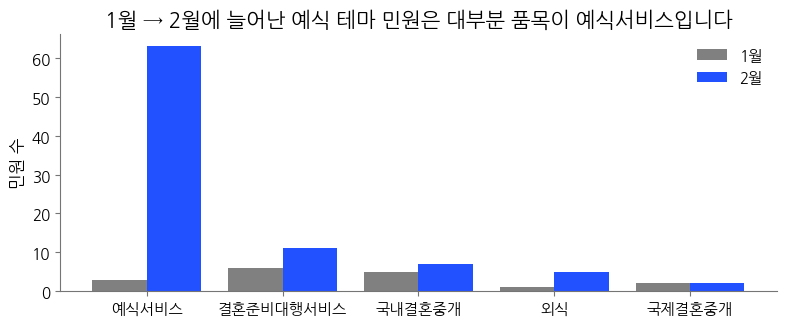

In [18]:
# 단계 3 · 그림: 예식 테마 1월과 2월 민원의 품목(2월에 많은 5개)
names = list(ITEMS[2].index[:5])
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(x - 0.2, [ITEMS[1].get(n, 0) for n in names], width=0.4, color="gray", label="1월")
ax.bar(x + 0.2, [ITEMS[2].get(n, 0) for n in names], width=0.4, color="#2251FF", label="2월")
ax.set_xticks(x, names)
ax.set_ylabel("민원 수")
ax.legend(frameon=False)
ax.set_title("1월 → 2월에 늘어난 예식 테마 민원은 대부분 품목이 예식서비스입니다")
plt.show()

In [19]:
# 단계 3: 예식 테마 2월 민원에서 무작위로 추출한 원문 10건(시드 0). 제목에 있는 상호는 「판매처 C」로 바꿔 보여 줍니다
SELLER_HASH = "ba6c831e077c"          # 바꿔 보여 줄 상호의 SHA-256 앞 12자리(상호 글자는 코드에 두지 않습니다)


def mask_seller(title):
    words = title.split()
    hits = [hashlib.sha256(w.encode()).hexdigest()[:12] == SELLER_HASH for w in words]
    return " ".join("판매처 C" if h else w for w, h in zip(words, hits)), any(hits)


FEB_WED = WED[WED["month"] == 2]
MASKED = FEB_WED["사건제목"].map(mask_seller)
FEB10 = MASKED.loc[FEB_WED.sample(10, random_state=0).index]
print("표 5 · 예식 테마 2월 민원에서 무작위로 추출한 원문 10건")
for i, (title, _) in enumerate(FEB10, 1):
    print(f"{i:>2}. {title}")
COVID = int(FEB_WED["사건제목"].str.contains("코로나").sum())
SELLER_C = int(sum(hit for _, hit in MASKED))
print(f"2월 예식 테마 민원 {len(FEB_WED)}건 가운데 제목에 「코로나」가 있는 민원: {COVID}건")
print(f"2월 예식 테마 민원 {len(FEB_WED)}건 가운데 제목에 판매처 C 상호가 있는 민원: {SELLER_C}건")

표 5 · 예식 테마 2월 민원에서 무작위로 추출한 원문 10건
 1. 코로나예식업해지문의
 2. 결혼중개업소에 배상 요청할 수 있는지 문의
 3. 예식장 계약 해지 관련 문의
 4. 코로나로 인한 결혼식 위약금 문의
 5. 코로나 이유로 예식 취소시 위약금 청구
 6. 예식장 사업자 귀책으로 취소되어 환급기준 문의와 손해배상 문의
 7. 예식장 계약취소시 위약금 관련 건
 8. 예식장 취소 후 위약금 문의
 9. 예식장 계약 후 코로나로 인하여 계약해지
10. 결혼중개업체 판매처 C 업체에 환불신청을 했으나 부당위약금 요구와 환불금 지연처리로 신청합니다.
2월 예식 테마 민원 92건 가운데 제목에 「코로나」가 있는 민원: 24건
2월 예식 테마 민원 92건 가운데 제목에 판매처 C 상호가 있는 민원: 1건


**직접 해 보기: 예식 테마 2월의 한 판매처 집중 여부**

- `MY_CONCENTRATED`: 예식 테마 2월의 증가가 한 판매처 집중이면 `True`, 아니면 `False`(따옴표 없이)
- `MY_WHY`: 그렇게 판단한 이유 한 문장(문자열). 같은 상호가 여러 번 나오는지와 비중이 0.5 를 넘는지를 이유로 적습니다.

In [20]:
# 단계 3 · 직접 해 보기: 한 판매처 집중인가(True · False) · 이유 한 문장
MY_CONCENTRATED = False
MY_WHY ="무작위 10건 가운데 제목에 판매처 C 상호와 같은 상호가 있는 민원: 1건 뿐이고, 비중이 0.5를 넘어서지도 않음"

In [21]:
# 단계 3 · 확인 셀: MY_CONCENTRATED 와 MY_WHY 에 있는 요소 3가지(상호 · 비중 · 기준 0.5)를 확인합니다
#  빈 칸 · 형식은 ac_state, 수 대조는 ac_has_value, 부정한 문장 거르기는 ac_claims, 요소 표 출력은 ac_show(설치 셀 끝의 공용 도우미)
def tell(name, msg):                                                     # ac_state 의 안내에 변수 이름을 넣는다
    print(msg.replace("고칠 것: ", f"고칠 것: {name} 는 ", 1) if msg.startswith("고칠") else f"{name}: {msg}")


def check_seller(conc, why):
    (c_ok, c_msg), (w_ok, w_msg) = ac_state(conc, "bool"), ac_state(why, "text")
    if c_msg == w_msg == ac_state(None)[1]:
        print("아직 채우지 않았습니다. 위 셀의 MY_CONCENTRATED · MY_WHY 를 채운 뒤 다시 실행합니다")
        return
    if "FEB_WED" not in globals():
        print("단계 3 의 셀(표 4 · 표 5)을 먼저 실행한 뒤 이 셀을 다시 실행합니다")
        return
    n, s = len(FEB_WED), SELLER_C / len(FEB_WED)
    if c_ok:
        print(f"MY_CONCENTRATED: {'맞았습니다' if conc is False else '아직 다릅니다'}. 무작위 원문 10건에 같은 상호가 여러 번 나오지 않고,"
              f" 판매처 C 의 비중은 {SELLER_C} ÷ {n} = {s:.3f} 로 0.5 보다 작습니다")
    else:
        tell("MY_CONCENTRATED", c_msg)
    if not w_ok:
        tell("MY_WHY", w_msg if w_msg.startswith("고칠") else w_msg + ". 판단한 이유를 한 문장으로 써 보세요")
    else:
        seller = re.search(r"상호|판매처|업체", why)
        repeat = re.search(r"여러 번|되풀이|반복|중복|겹|다시 나오|한 번|\d+\s?건뿐|한 건뿐|하나뿐|같은 (?:상호|판매처|업체)", why)
        ac_show("MY_WHY 에 있는 요소", {
            "상호(같은 판매처가 여러 번 나오는가)": seller and repeat,   # 판매처 이름만 있고 여러 번 나오는지에 대한 판단이 없으면 없음
            "비중": "비중" in why,
            "기준 0.5(절반)": ac_has_value(why, 0.5, digits=2) or re.search(r"절반|(?<!\d)50\s?%", why)})
        if seller and not repeat:
            print("  같은 상호가 여러 번 나오는지에 대한 판단이 없습니다. 무작위 원문 10건에서 같은 상호가 여러 번 나왔는지 적습니다")
        if ac_claims(why, re.compile(r"품목|예식서비스")):                  # 품목을 부정하거나 확인할 일로 쓴 문장은 빼고 찾는다
            print("  품목의 비중은 한 판매처의 비중이 아닙니다. 품목은 상품의 종류라 한 품목에 여러 판매처가 있습니다")
    if not (c_ok or w_ok):
        return
    named = sum(hit for _, hit in FEB10)
    print(f"무작위 10건 가운데 상호가 나온 판매처는 판매처 C {named}건뿐이고, 다른 {len(FEB10) - named}건은 제목에 상호가 없습니다."
          f" 늘어난 것은 원문 제목에 나온 대로 코로나로 인한 예식 취소와 위약금 민원입니다({n}건 가운데 {COVID}건의 제목에 「코로나」)")


check_seller(globals().get("MY_CONCENTRATED"), globals().get("MY_WHY", ""))

MY_CONCENTRATED: 맞았습니다. 무작위 원문 10건에 같은 상호가 여러 번 나오지 않고, 판매처 C 의 비중은 1 ÷ 92 = 0.011 로 0.5 보다 작습니다
MY_WHY 에 있는 요소: 3가지 가운데 3가지
  상호(같은 판매처가 여러 번 나오는가): 있음
  비중: 있음
  기준 0.5(절반): 있음
무작위 10건 가운데 상호가 나온 판매처는 판매처 C 1건뿐이고, 다른 9건은 제목에 상호가 없습니다. 늘어난 것은 원문 제목에 나온 대로 코로나로 인한 예식 취소와 위약금 민원입니다(92건 가운데 24건의 제목에 「코로나」)


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_CONCENTRATED = False`

`MY_WHY = "무작위 원문 10건에 같은 상호가 여러 번 나오지 않고, 판매처 C 의 비중도 1 ÷ 92 = 0.011 로 0.5 보다 작다"`

- 10건 가운데 상호가 있는 제목은 판매처 C 1건뿐입니다. 다른 9건은 예식장 계약의 해지 · 취소 · 위약금이나 결혼중개에 관한 민원이고, 제목에 상호가 없습니다.
- 품목 예식서비스의 비중 0.685 는 0.5 를 넘지만, 품목은 상품의 종류라 한 판매처의 비중이 아닙니다.
- 무작위 10건 가운데 4건의 제목에 「코로나」가 있고, 4건 모두 예식 계약의 해지 · 취소나 위약금에 관한 민원입니다.

</details>

> **[문제] 예식 테마 2월 증가는 한 판매처 집중인가**
>
> 「표 4 · 예식 테마 1월과 2월 민원의 품목 상위 3 (건, 비중)」과 「표 5 · 예식 테마 2월 민원에서 무작위로 추출한 원문 10건」에서, 예식 테마 2월의 증가를 한 판매처 집중으로 분류할까요?
>
> 1. 분류한다: 1위 품목 예식서비스의 비중이 0.5 를 넘는다
> 2. 분류하지 않는다: 원문 10건에 같은 상호가 되풀이되지 않는다
> 3. 분류한다: 원문 10건 가운데 「코로나」가 있는 제목이 여럿이다

> **[문제] 무작위 원문 10건 가운데 한 판매처가 3건일 때**
>
> 예를 들어 어느 테마의 9월이 원문을 확인할 달이고, 그 테마의 9월 민원은 200건입니다. 무작위 원문 10건 가운데 판매처 X 가 3건이었고, 그 테마의 9월 민원 200건에서 판매처 X 를 모두 찾으니 120건입니다. 이 증가는 어떻게 다룰까요?
>
> 1. 한 판매처 집중이 아니다: 읽은 10건 가운데 3건이라 비중이 0.3 이다
> 2. 한 판매처 집중이다: 판매처 표시 열에 판매처 X 를 기록하고 판매처 X 를 뺀 비율도 구한다
> 3. 한 판매처 집중이다: 판매처 X 의 민원을 지우고 남은 80건으로 추이를 그린다

## 단계 4 버전 기록

- **할 일**: `MY_VERSION` 의 대상 · 이름과 번호 · 만든 날짜 · 바뀐 것을 채웁니다.
- **연습하는 것**: 코드북을 고친 뒤 고치기 전 결과와 비교할 수 있게 버전을 남기는 법

토픽을 검증하고 코드북을 만들 때, 이름 확인에서 읽은 예식 테마 원문을 바탕으로 예식 테마의 기준을 다시 썼습니다. 다시 쓴 코드북은 코드북 v0 과 기준이 달라, 새 버전으로 기록합니다.

| 항목 | 코드북 v0 | 다시 쓴 기준 |
|---|---|---|
| 정의 | 예식 취소·위약금에 관한 민원 | 예식장·웨딩홀·결혼준비대행 계약을 취소·연기·변경하면서 생긴 위약금·계약금 문제에 관한 민원 |
| 포함 기준 | 제목·품목명이 이 이름에 들어맞는 민원 | 민원 제목이 예식 계약의 취소·연기·인원 조정이나 그에 따른 위약금·계약금 환급에 관한 민원 |
| 제외 기준 | 다른 테마 이름이 더 잘 맞는 민원 → 그 테마, 어디에도 맞지 않으면 기타 | 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비는 예식 계약이 아니라 기타 |

테마 이름 「예식 취소·위약금」과 코드북의 예시는 코드북 v0 그대로입니다. 포함 기준은 「제목·품목명」 대신 민원 제목으로 판단하고, 연기 · 인원 조정 · 계약금 환급을 포함합니다.

버전 열에는 대상 · 이름과 번호 · 만든 날짜 · 앞 버전에서 바뀐 것, 항목 4개를 남깁니다. 이름과 번호만으로는 앞 버전에서 무엇이 바뀌었는지 알 수 없기 때문입니다.

- 대상: 사전 · 코드북 · 토픽 배정 · 프롬프트 · 모델 가운데 무엇인지
- 이름과 번호: 코드북 v0 의 이름 `codebook-v0-20260924` 처럼 번호와 만든 날짜를 포함한 이름
- 만든 날짜: 새 코드북을 만든 날짜(연-월-일)
- 앞 버전에서 바뀐 것: 한 문장

자료 준비의 버전 열에는 버전 이름만 있습니다. 이 단계에서는 다시 쓴 코드북의 버전 열 항목 4개를 모두 채웁니다.

이 실습의 테마 열은 토픽 번호로 정해, 코드북을 고쳐도 그대로입니다. 다시 분류하는 것은 고친 코드북을 프롬프트에 입력해 LLM 으로 분류할 때입니다. 그때는 1월부터 모든 달을 새 기준으로 다시 분류해 옛 값과 비교합니다. 고친 달부터만 새 기준을 쓰면, 기준을 바꿔 생긴 차이가 민원의 변화처럼 보이기 때문입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/0/09/Semantic-versioning.svg" alt="v2.21.2 의 세 수에 각각 Major, Minor, Patch 라는 이름과 설명이 있는 그림" width="400" height="400"/>
<p align="center"><em>▲ 버전 이름 v2.21.2 의 숫자 3개다. 앞 수(Major)는 이전 결과와 맞지 않게 되는 변경, 가운데(Minor)는 기능 추가, 끝(Patch)은 오류 수정이다. 코드북의 기준을 다시 쓴 것은 앞 수가 바뀌는 변경에 가깝다 (출처: Wikimedia Commons 「Semantic-versioning.svg」, Surjit Bains, CC BY-SA 4.0)</em></p>

In [22]:
# 단계 4: 테마 비율표가 쓴 버전. 버전 열의 값이 하나면 한 표 안의 값이 모두 같은 버전입니다
print(f"버전 열의 값과 민원 수(민원 표본 {len(SAMPLE):,}건)")
for ver, k in SAMPLE["ver"].value_counts().items():
    print(f"  {ver}: {k:,}건")
w = "예식 취소·위약금"
print(f"예식 테마 2월 비율: {COUNTS.loc[w, 2]} ÷ {N_MONTH[2]:,} = {fmt(100 * SHARE.loc[w, 2], 2)}%"
      " · 테마 열은 토픽 배정의 토픽 6 을 코드북 v0 의 이름으로 바꾼 값")

버전 열의 값과 민원 수(민원 표본 20,000건)
  topics-v1-20260924 (시드 0) / codebook-v0-20260924: 20,000건
예식 테마 2월 비율: 92 ÷ 2,410 = 3.82% · 테마 열은 토픽 배정의 토픽 6 을 코드북 v0 의 이름으로 바꾼 값


**직접 해 보기: 다시 쓴 코드북의 버전 열**

`MY_VERSION` 의 항목 4개를 채웁니다. 새 코드북을 만든 날짜는 2026-10-26 입니다. 항목 이름은 그대로 두고, 따옴표 안의 값만 적습니다.

In [23]:
# 단계 4 · 직접 해 보기: 예식 테마 기준을 다시 쓴 코드북의 버전 열 항목 4개(따옴표 안에 적습니다)
MY_VERSION = {"대상": "코드북", "이름과 번호": "codebook-v1-20261026", "만든 날짜": "2026-10-26", "바뀐 것": "예식장·웨딩홀·결혼준비대행 계약을 취소·연기·변경하면서 생긴 위약금·계약금 문제에 관한 민원으로 정의, 민원 제목이 예식 계약의 취소·연기·인원 조정이나 그에 따른 위약금·계약금 환급에 관한 민원 포함, 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비는 예식 계약이 아니라 기타로 취급"}

In [24]:
# 단계 4 · 확인 셀: MY_VERSION 의 항목 4개를 채웠는지, 대상 · 번호 · 날짜 형식과 이름 속 날짜가 맞는지 확인합니다
#  빈 칸 · 형식은 ac_state(설치 셀 끝의 공용 도우미)
KEYS = ["대상", "이름과 번호", "만든 날짜", "바뀐 것"]
V0_DAY = "2026-09-24"                                                    # 코드북 v0 을 만든 날짜(codebook-v0-20260924)
CHANGES = {"연기": "연기", "인원 조정": "인원", "계약금 환급": "계약금", "민원 제목으로 판단": "민원 제목",
           "돌잔치": "돌잔치", "뷔페": "뷔페", "결혼정보업체 가입비": "결혼정보|가입비"}   # 다시 쓴 기준에서 달라진 요소


def check_version(ver):
    st = {k: ac_state(v) for k, v in ver.items()} if isinstance(ver, dict) else {}   # 항목마다 (채웠는가, 안내)
    empty_msg = ac_state(None)[1]
    if ver is None or isinstance(ver, dict) and all(m == empty_msg for _, m in st.values()):
        print("아직 채우지 않았습니다. 위 셀의 MY_VERSION 항목 4개를 채운 뒤 다시 실행합니다")
        return
    if "SHARE" not in globals():
        print("「자료 준비」 셀을 먼저 실행한 뒤 이 셀을 다시 실행합니다")
        return
    if not isinstance(ver, dict):
        print('고칠 것: MY_VERSION 은 중괄호 안에 {"대상": "…", "이름과 번호": "…", "만든 날짜": "…", "바뀐 것": "…"} 처럼 적습니다')
        return
    lost = [k for k in KEYS if k not in ver]
    if lost:
        print(f"고칠 것: 항목 {' · '.join('「' + k + '」' for k in lost)}이 없습니다. 위 셀의 항목 이름 4개를 그대로 둡니다")
        return
    val = {k: ver[k].strip() if st[k][0] else "" for k in KEYS}
    empty = [k for k in KEYS if st[k][1] == empty_msg]
    wrong = [k for k in KEYS if not st[k][0] and st[k][1] != empty_msg]                # 따옴표 없이 적은 항목
    print(f"버전 열 항목 4개 가운데 {4 - len(empty) - len(wrong)}개를 채웠습니다" + (f"(빈 항목: {' · '.join(empty)})" if empty else ""))
    if wrong:
        print(f"고칠 것: 항목 {' · '.join('「' + k + '」' for k in wrong)}의 값을 따옴표 안에 적습니다")
    if val["대상"]:
        print("  대상: " + ("코드북이 맞습니다" if "코드북" in val["대상"] else
                          "기준을 다시 쓴 것은 사전 · 토픽 배정 · 프롬프트 · 모델이 아니라 코드북입니다"))
    if val["이름과 번호"]:
        num = re.search(r"v(\d+)", val["이름과 번호"])
        print("  이름과 번호: " + ("번호가 없습니다. codebook-v0-20260924 처럼 v 뒤에 번호를 씁니다" if not num else
                               "고친 코드북은 v0 이 아닌 새 번호를 씁니다" if num.group(1) == "0" else
                               "새 번호가 있습니다" + ("" if "codebook" in val["이름과 번호"] else
                                                   ". codebook-v0-20260924 처럼 대상과 만든 날짜도 이름에 포함하면 파일만 보고도 찾을 수 있습니다")))
    if val["만든 날짜"]:
        ok = re.fullmatch(r"\d{4}-\d{2}-\d{2}", val["만든 날짜"])
        in_name = re.search(r"(\d{4})-?(\d{2})-?(\d{2})", val["이름과 번호"])
        name_day = "-".join(in_name.groups()) if in_name else None          # 이름 속 날짜(연-월-일)
        print("  만든 날짜: " + ("연-월-일 형식(○○○○-○○-○○)으로 적습니다" if not ok else
                             f"{V0_DAY} 는 코드북 v0 을 만든 날짜입니다. 새 코드북을 만든 날짜를 적습니다" if val["만든 날짜"] == V0_DAY else
                             f"이름 속 날짜({name_day})와 다릅니다. 이름과 만든 날짜에 같은 날짜를 적습니다"
                             if name_day and name_day != val["만든 날짜"] else
                             "연-월-일 형식이고, 이름 속 날짜와 같습니다" if name_day else "연-월-일 형식입니다"))
    if val["바뀐 것"]:
        found = [k for k, pat in CHANGES.items() if re.search(pat, val["바뀐 것"])]
        print(f"  바뀐 것: 다시 쓴 기준에서 달라진 요소 {len(CHANGES)}가지({' · '.join(CHANGES)}) 가운데 {len(found)}가지가 있습니다")
        if len(found) < 2:
            print("  다시 쓴 기준표에서 포함 기준과 제외 기준이 어떻게 바뀌었는지 적습니다")
    w = "예식 취소·위약금"
    print(f"테마 열은 토픽 번호로 정해 코드북을 고쳐도 1～9월 테마 비율은 그대로입니다(예식 테마 2월 {fmt(100 * SHARE.loc[w, 2], 2)}%)."
          " 다시 분류하는 것은 고친 코드북을 프롬프트에 입력해 LLM 으로 분류할 때입니다.")


check_version(globals().get("MY_VERSION"))

버전 열 항목 4개 가운데 4개를 채웠습니다
  대상: 코드북이 맞습니다
  이름과 번호: 새 번호가 있습니다
  만든 날짜: 연-월-일 형식이고, 이름 속 날짜와 같습니다
  바뀐 것: 다시 쓴 기준에서 달라진 요소 7가지(연기 · 인원 조정 · 계약금 환급 · 민원 제목으로 판단 · 돌잔치 · 뷔페 · 결혼정보업체 가입비) 가운데 7가지가 있습니다
테마 열은 토픽 번호로 정해 코드북을 고쳐도 1～9월 테마 비율은 그대로입니다(예식 테마 2월 3.82%). 다시 분류하는 것은 고친 코드북을 프롬프트에 입력해 LLM 으로 분류할 때입니다.


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

```text
MY_VERSION = {"대상": "코드북", "이름과 번호": "codebook-v1-20261026", "만든 날짜": "2026-10-26",
              "바뀐 것": "원문을 바탕으로 예식 테마의 기준을 다시 써, 포함 기준은 민원 제목으로 판단하고 연기 · 인원 조정 · 계약금 환급을 포함하며 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비는 기타로 뺌"}
```

- 대상은 코드북입니다. 사전 · 토픽 배정 · 프롬프트 · 모델은 바뀌지 않았습니다.
- 번호는 v0 다음인 v1 이고, 이름은 v0 처럼 번호와 만든 날짜로 짓습니다.
- 바뀐 것에는 위 표에서 달라진 요소를 적습니다. 포함 기준에서는 민원 제목으로 판단하는 것과 연기 · 인원 조정 · 계약금 환급이, 제외 기준에서는 돌잔치 · 뷔페 · 결혼정보업체 가입비가 달라졌습니다.
- 고친 코드북을 프롬프트에 입력해 LLM 으로 다시 분류하면, 이 요소가 있는 민원은 v0 과 다른 테마가 될 수 있습니다. 이 실습의 테마 열은 토픽 번호로 정해, 코드북을 고쳐도 그대로입니다.

</details>

> **[문제] 코드북을 고친 뒤 버전 열에 남길 것**
>
> 이름 확인에서 읽은 원문을 바탕으로 코드북 v0 의 예식 테마 기준을 다시 쓴 새 코드북을 2026-10-26 에 만들었습니다. 포함 기준에 연기를, 제외 기준에 돌잔치 · 뷔페 계약의 취소와 결혼정보업체 가입비를 적었습니다. 이 코드북의 버전 열 항목 4개를 채우고, 이 코드북으로 LLM 분류를 할 때 다시 할 일도 한 문장으로 써 보세요.

## 결론

예식 테마 2월에 아직 확인하지 않은 달력과 버전을 봅니다.

In [25]:
# 결론: 예식 테마 2월이 잘린 달인지(단계 2 처럼 앞 달 영업일당 건수의 절반이 기준), 1월과 2월 비율이 같은 버전인지 확인합니다
jan, feb = DAILY["2020-01-01":"2020-01-31"], DAILY["2020-02-01":"2020-02-29"]
jan_rate = jan.sum() / is_biz(jan.index).sum()                           # 1월 영업일당 건수
feb_biz = feb[is_biz(feb.index)]
low = int((feb_biz < jan_rate / 2).sum())                                # 2월 영업일 가운데 1월 영업일당 건수의 절반 아래인 날
print(f"1월 영업일당 건수: {jan.sum():,}건 ÷ 영업일 {is_biz(jan.index).sum()}일 = {fmt(jan_rate, 1)}건")
print(f"2월 영업일 {len(feb_biz)}일 가운데 1월 영업일당 건수의 절반({fmt(jan_rate / 2, 1)}건) 아래로 떨어진 날이 "
      + ("없어 끊긴 날이 없습니다" if low == 0 else f"{low}일 있습니다") + f"(가장 적은 날 {int(feb_biz.min()):,}건)")
vers = SAMPLE[(SAMPLE["theme"] == "예식 취소·위약금") & SAMPLE["month"].isin([1, 2])]["ver"].unique()
print(f"예식 테마 1월 · 2월 민원의 버전 열: {' · '.join(vers)} ({len(vers)}가지)")

1월 영업일당 건수: 52,337건 ÷ 영업일 20일 = 2,616.9건
2월 영업일 20일 가운데 1월 영업일당 건수의 절반(1,308.4건) 아래로 떨어진 날이 없어 끊긴 날이 없습니다(가장 적은 날 2,304건)
예식 테마 1월 · 2월 민원의 버전 열: topics-v1-20260924 (시드 0) / codebook-v0-20260924 (1가지)


- 2월 영업일 20일 가운데 1월 영업일당 건수의 절반(1,308.4건) 아래로 떨어진 날이 없어 끊긴 날이 없습니다. 가장 적은 날도 2,304건입니다. 2월은 잘린 달이 아닙니다. 비율은 같은 달 표본끼리 나눈 값이라, 영업일 수가 달라도 그대로입니다.
- 1월과 2월 비율은 같은 버전으로 계산했습니다. 버전이 바뀌어 생긴 증가가 아닙니다.

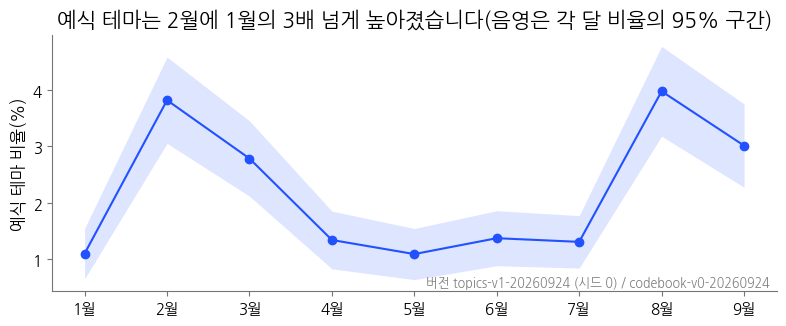

In [26]:
# 결론 · 그림: 예식 테마의 1～9월 비율과 각 달 비율의 95% 구간(10월은 잘린 달이라 뺌)
p = SHARE.loc["예식 취소·위약금"]
h = 1.96 * np.sqrt(p * (1 - p) / N_MONTH)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(p.index, 100 * (p - h), 100 * (p + h), color="#2251FF", alpha=0.15, linewidth=0)
ax.plot(p.index, 100 * p, "o-", color="#2251FF")
ax.set_xticks(p.index, [f"{m}월" for m in p.index])
ax.set_ylabel("예식 테마 비율(%)")
ax.text(0.99, 0.02, f"버전 {SAMPLE['ver'].iloc[0]}", transform=ax.transAxes, ha="right", fontsize=9, color="gray")
ax.set_title("예식 테마는 2월에 1월의 3배 넘게 높아졌습니다(음영은 각 달 비율의 95% 구간)")
plt.show()

그림에서 8월도 7월보다 높습니다. 8월도 원문을 확인할 달일까요?

In [27]:
# 결론: 예식 테마 8월을 두 조건(앞 달 대비 1.5배 이상 · 두 달 차이의 95% 구간)으로 확인합니다
p, n = SHARE.loc["예식 취소·위약금"], N_MONTH
moe = 1.96 * np.sqrt(p[7] * (1 - p[7]) / n[7] + p[8] * (1 - p[8]) / n[8])
print(f"예식 테마 7월 → 8월: {fmt(100 * p[7], 2)}% → {fmt(100 * p[8], 2)}% · 앞 달 대비 {p[8] / p[7]:.3f}배"
      f" · 두 달 차이의 95% 구간 {fmt(100 * (p[8] - p[7] - moe), 2)}～{fmt(100 * (p[8] - p[7] + moe), 2)}%p")

예식 테마 7월 → 8월: 1.31% → 3.98% · 앞 달 대비 3.044배 · 두 달 차이의 95% 구간 1.75～3.59%p


8월도 두 조건을 모두 만족해 원문을 확인할 달입니다. 8월에 늘어난 민원이 무엇인지는 원문을 읽어 봐야 합니다.

<div class="lms-summary">

**정리**

- 분모: 예식 테마 2월의 비율이 오른 것은 분모가 줄어서가 아니라 건수가 4배로 늘었기 때문입니다.
- 구간과 배수: 테마 4개 가운데 두 달 차이의 95% 구간이 0 을 포함하지 않는 것은 3개입니다. 원문을 확인할 달은 표 1 의 정수기 테마 7월 · 예식 테마 2월과 결론에서 더한 예식 테마 8월입니다.
- 달력: 10월 월 건수가 9월보다 81.8% 적은 것은 접수가 10-08 을 끝으로 끊긴 탓입니다. 10-01～10-08 의 영업일당 건수는 2,297.8건으로 9월 2,457.9건과 비슷합니다. 2월은 잘린 달이 아닙니다.
- 원문: 예식 테마 2월은 무작위 원문 10건에 같은 상호가 여러 번 나오지 않아 한 판매처 집중으로 보지 않습니다. 정수기 테마 7월과 예식 테마 8월은 무엇이 늘었는지 원문을 읽어 봐야 합니다.
- 버전: 예식 테마 1월과 2월 비율은 같은 버전으로 계산했습니다. 예식 테마의 기준을 다시 쓴 코드북은 codebook-v1 로 기록합니다. 테마 열은 토픽 번호로 정해 1～9월 테마 비율은 그대로이고, 고친 코드북은 LLM 으로 분류할 때 프롬프트에 입력합니다.

**앞으로 분석할 때 할 일**

- 원문을 확인할 달은 앞 달 대비 1.5배 이상과 두 달 차이의 95% 구간이 0 을 포함하지 않는다는 두 조건으로 고릅니다
- 잘린 달은 일별 건수로 접수가 이어진 마지막 날을 찾고, 테마 비율표에서 뺍니다
- 비율 옆에는 토픽 배정과 코드북의 버전을 남깁니다

예식 테마 2월의 증가는 분모 · 달력 · 한 판매처 집중 · 버전으로 설명되지 않는 주제의 변화입니다. 늘어난 것은 코로나로 인한 예식 취소와 위약금 민원입니다.

</div>

> **[과제] 실습 제출: 테마 비율이 바뀐 달에서 확인할 4가지**
>
> 단계마다 있는 직접 해 보기를 모두 채우고 확인 셀을 실행한 상태로 노트북을 제출합니다. ① 단계 1 의 MY_BEYOND · MY_CHECK ② 단계 2 의 MY_LAST_DAY · MY_BIZ_RATE ③ 단계 3 의 MY_CONCENTRATED · MY_WHY ④ 단계 4 의 MY_VERSION 을 채웁니다. 답이 예시 답과 달라도 확인 셀이 결과를 출력했으면 점수를 받습니다.
>
> 마감: 2026-11-12T23:59+09:00
>
> **평가 기준**
>
> | 기준 | 이렇게 하면 충족 | 배점 |
> | --- | --- | --- |
> | 단계 1 | MY_BEYOND · MY_CHECK 를 채웠고 확인 셀이 테마마다 두 조건의 결과를 출력했다 | 25 |
> | 단계 2 | MY_LAST_DAY · MY_BIZ_RATE 를 채웠고 확인 셀이 두 값의 결과와 10월 결론을 출력했다 | 25 |
> | 단계 3 | MY_CONCENTRATED · MY_WHY 를 채웠고 확인 셀이 결론과 MY_WHY 에 있는 요소를 출력했다 | 25 |
> | 단계 4 | MY_VERSION 항목 4개를 채웠고 확인 셀이 버전 열 항목을 출력했다 | 25 |
>
> 제출은 LMS 레슨 화면의 과제 카드에서 GitHub 링크로 합니다(이 파일에 적으면 제출되지 않습니다).

<div style="background:#F2F2F2;color:#000000;padding:28px;border-radius:12px;border:1px solid #E6E6E6;margin-top:16px;border-left:4px solid #051C2C">
<h2 style="color:#000000;margin:0 0 8px 0">수고했습니다. 비정형 데이터(자연어) 월별 테마 추이 실습을 마쳤습니다</h2>
<div style="color:#656565">테마 4개마다 두 달의 비율을 두 조건으로 비교했고, 10월 건수가 줄어든 이유를 일별 건수로 찾았습니다. 예식 테마 2월의 원문을 읽고, 기준을 고친 코드북을 버전으로 기록했습니다.</div>
</div>